In [6]:
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.express as px
import pandas as pd
import glob 
import os
import pickle

from data_process import select_df,fac_decompose_dB,read_and_process_data

# plotting routine

In [11]:
def plot(df):
    fig=make_subplots(rows=4,cols=1,

                  shared_xaxes='all',
                #   shared_yaxes='all',
                  vertical_spacing=0.01)
    fig.add_trace(go.Scatter(x=pd.to_datetime(df['TIME']),y=df['BR'],mode='lines',name='BR'),row=1,col=1)
    fig.add_trace(go.Scatter(x=pd.to_datetime(df['TIME']),y=df['BTHETA'],mode='lines',name='BTHETA'),row=2,col=1)
    fig.add_trace(go.Scatter(x=pd.to_datetime(df['TIME']),y=df['BPHI'],mode='lines',name='BPHI'),row=3,col=1)
    fig.add_trace(go.Scatter(x=pd.to_datetime(df['TIME']),y=df['BTOTAL'],mode='lines',name='BTOTAL'),row=4,col=1)

    fig.update_xaxes(title_text="Time",row=4,col=1)
    fig.update_yaxes(title_text="BR (nT)",row=1,col=1)
    fig.update_yaxes(title_text="BTHETA (nT)",row=2,col=1)
    fig.update_yaxes(title_text="BPHI (nT)",row=3,col=1)
    fig.update_yaxes(title_text="BTOTAL (nT)",row=4,col=1)


    fig.update_layout(height=800,title_text="Magnetic Field Components over Time")
    fig.show()


    # use plotly to visualize dB in one figure with no subplots
    opacity=0.5
    fig = go.Figure()
    fig.add_trace(go.Scatter(x=df['TIME'], y=df['dB_parallel'], mode='lines', name='dB_parallel',opacity=0.5))
    fig.add_trace(go.Scatter(x=df['TIME'], y=df['dB_perpendicular_1'], mode='lines', name='dB_perpendicular_1',opacity=0.5,))
    fig.add_trace(go.Scatter(x=df['TIME'], y=df['dB_perpendicular_2'], mode='lines', name='dB_perpendicular_2',opacity=0.5,))
    fig.update_layout(title='Magnetic Field Fluctuations',
                    xaxis_title='Time',
                    yaxis_title='dB (nT)')
    fig.show()

    # visualize dB
    fig=go.Figure()
    fig.add_trace(go.Scatter(x=df['TIME'], y=df['dB_R'], mode='lines', name='dB_R',opacity=0.5))
    fig.add_trace(go.Scatter(x=df['TIME'], y=df['dB_THETA'], mode='lines', name='dB_THETA',opacity=0.5))
    fig.add_trace(go.Scatter(x=df['TIME'], y=df['dB_PHI'], mode='lines', name='dB_PHI',opacity=0.5))
    fig.update_layout(title='Magnetic Field Fluctuations Components',
                    xaxis_title='Time',
                    yaxis_title='dB Components (nT)')            
    fig.show()

    # B
    fig=make_subplots(rows=4,cols=1,
                        shared_xaxes='all',
                        # shared_yaxes='all',
                        vertical_spacing=0.05)
    fig.add_trace(go.Scatter(x=pd.to_datetime(df['TIME']),y=df['BR'],mode='lines',name='BR'),row=1,col=1)
    fig.add_trace(go.Scatter(x=pd.to_datetime(df['TIME']),y=df['BTHETA'],mode='lines',name='BTHETA'),row=2,col=1)

    fig.add_trace(go.Scatter(x=pd.to_datetime(df['TIME']),y=df['BPHI'],mode='lines',name='BPHI'),row=3,col=1)
    fig.add_trace(go.Scatter(x=pd.to_datetime(df['TIME']),y=df['BTOTAL'],mode='lines    ',name='BTOTAL'),row=4,col=1)   
    fig.show()

    #b_hat
    fig=go.Figure()
    fig.add_trace(go.Scatter(x=pd.to_datetime(df['TIME']),y=df['b_hat_R'],mode='lines',name='b_hat_R'))
    fig.add_trace(go.Scatter(x=pd.to_datetime(df['TIME']),y=df['b_hat_THETA'],mode='lines',name='b_hat_THETA'))
    fig.add_trace(go.Scatter(x=pd.to_datetime(df['TIME']),y=df['b_hat_PHI'],mode='lines',name='b_hat_PHI'))      
    fig.show()



# Meeks et al., 2016

### 21 DEC 2010 03:00-03:10

In [12]:
start_time=pd.to_datetime('2010-12-21 02:50:00')
end_time=pd.to_datetime('2010-12-21 03:20:00')

df=read_and_process_data(start_time,end_time)



In [13]:
df

,TIME,BR,BTHETA,BPHI,BTOTAL,NPTS,B0_R,B0_THETA,B0_PHI,B0_TOTAL,...,dB_THETA,dB_PHI,dB_TOTAL,b_hat_R,b_hat_THETA,b_hat_PHI,dB_parallel,dB_perpendicular,dB_perpendicular_1,dB_perpendicular_2
0,2010-12-21 03:00:00.500,-3.981,190.717,-0.115,190.758,16,-4.133346,190.659878,-0.175117,190.704757,...,0.057122,0.060117,0.173454,-0.021674,0.999765,-0.000918,0.053751,0.164915,0.153547,-0.060169
1,2010-12-21 03:00:01.500,-4.109,190.753,0.013,190.798,16,-4.132668,190.643682,-0.175085,190.688550,...,0.109318,0.188085,0.218830,-0.021672,0.999765,-0.000918,0.108606,0.189977,0.026027,-0.188185
2,2010-12-21 03:00:02.500,-4.251,190.756,-0.064,190.804,16,-4.132125,190.627467,-0.174842,190.672326,...,0.128533,0.110842,0.207215,-0.021671,0.999765,-0.000917,0.130978,0.160570,-0.116064,-0.110960
3,2010-12-21 03:00:03.500,-4.201,190.706,-0.186,190.752,16,-4.131766,190.611191,-0.174665,190.656047,...,0.094809,-0.011335,0.117943,-0.021671,0.999765,-0.000916,0.096298,0.068098,-0.067163,0.011248
4,2010-12-21 03:00:04.500,-4.050,190.651,-0.235,190.695,16,-4.131389,190.594957,-0.174733,190.639809,...,0.056043,-0.060267,0.115746,-0.021671,0.999765,-0.000917,0.054321,0.102207,0.082586,0.060215
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
595,2010-12-21 03:09:55.500,-3.849,180.950,-0.307,180.991,8,-3.790669,181.261327,-0.160054,181.301030,...,-0.311327,-0.146946,0.349170,-0.020908,0.999781,-0.000883,-0.309909,0.160861,-0.064825,0.147221
596,2010-12-21 03:09:56.500,-3.905,180.971,-0.297,181.013,8,-3.790041,181.245952,-0.159893,181.285645,...,-0.274952,-0.137107,0.328043,-0.020906,0.999781,-0.000882,-0.272367,0.182835,-0.120680,0.137350
597,2010-12-21 03:09:57.500,-3.968,181.021,-0.347,181.065,8,-3.789462,181.230517,-0.159436,181.270201,...,-0.209517,-0.187564,0.333097,-0.020905,0.999781,-0.000880,-0.205573,0.262094,-0.182876,0.187748
598,2010-12-21 03:09:58.500,-3.948,181.074,-0.375,181.117,8,-3.789223,181.215108,-0.158832,181.254789,...,-0.141108,-0.216168,0.303068,-0.020906,0.999781,-0.000876,-0.137568,0.270047,-0.161688,0.216292


In [14]:
plot(df)

### 14 OCT 2009 01:10-01:20

In [5]:
start_time=pd.to_datetime('2009-10-14 01:00:00')
end_time=pd.to_datetime('2009-10-14 01:30:00')

df=select_df(start_time,end_time)
df=fac_decompose_dB(df,start_time,end_time)


/Users/chengzhimao/Documents/Code/saturn2025/data_process.py:28: FutureWarning:

The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.

/Users/chengzhimao/Documents/Code/saturn2025/data_process.py:28: FutureWarning:

The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.



In [6]:
plot(df)

### 21 DEC 2010 02:30-02:40

In [7]:
start_time=pd.to_datetime('2010-12-21 02:20:00')
end_time=pd.to_datetime('2010-12-21 02:50:00')

df=select_df(start_time,end_time)
df=fac_decompose_dB(df,start_time,end_time)

/Users/chengzhimao/Documents/Code/saturn2025/data_process.py:28: FutureWarning:

The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.

/Users/chengzhimao/Documents/Code/saturn2025/data_process.py:28: FutureWarning:

The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.



In [8]:
plot(df)

# Russell et al., 2006

In [ ]:
start_time=pd.to_datetime('2005-12-23 18:00:00')
end_time=pd.to_datetime('2005-12-24 18:00:00')

df=select_df(start_time,end_time)
df=fac_decompose_dB(df,start_time,end_time)

/Users/chengzhimao/Documents/Code/saturn2025/data_process.py:28: FutureWarning:

The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.

/Users/chengzhimao/Documents/Code/saturn2025/data_process.py:28: FutureWarning:

The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.



In [12]:
plot(df)

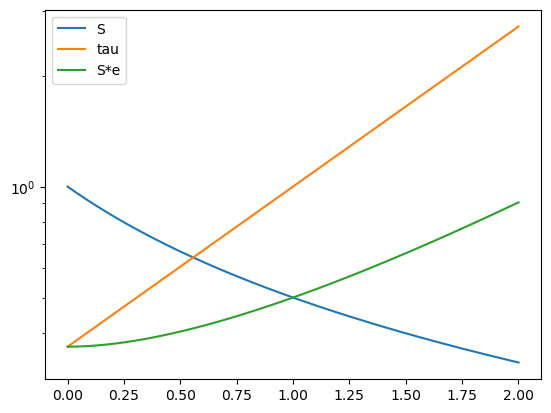

In [21]:
import numpy as np
import matplotlib.pyplot as plt
tau=1
t=np.linspace(0,2,1000)
S=1/(1+t)


e=np.exp(t-tau)
fig, ax = plt.subplots()
ax.plot(t, S,label="S")
ax.plot(t, e,label="tau")
ax.plot(t, S*e,label="S*e")
ax.set_yscale('log')
ax.legend()

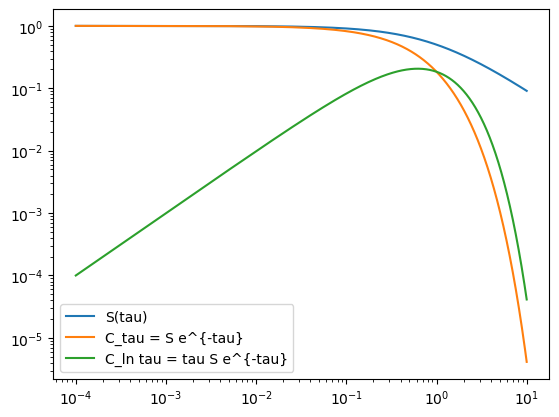

In [22]:
import numpy as np
import matplotlib.pyplot as plt

mu = 1.0
tau = np.linspace(1e-4, 10, 2000)   # start >0 if you want log-tau things

S = 1/(1+tau)            # your example (decreasing)
atten = np.exp(-tau/mu)  # correct attenuation

C_tau = S * atten / mu           # contribution per d tau
C_lntau = S * tau * atten / mu   # contribution per d(ln tau)

fig, ax = plt.subplots()
ax.plot(tau, S, label="S(tau)")
ax.plot(tau, C_tau, label="C_tau = S e^{-tau}")
ax.plot(tau, C_lntau, label="C_ln tau = tau S e^{-tau}")
ax.set_xscale('log')
ax.set_yscale('log')
ax.legend()
plt.show()
